# Lab 9 – Algorithmic Fairness of Predictive Models

Today we will look at different notions of fairness for predictive models.

We will work through a running example using the **Adult** dataset, where the goal is to predict whether a person's income is above \$50K per year.

# Fairness Notions

When machine learning models are used to make decisions about people (hiring, lending, admissions), they cannot be separated from the social and ethical context in which they are applied. Those who develop and deploy such models must account for both **performance** and **fairness**.

As a result, fairness has become one of the most active research areas in machine learning over the last decade.

The two main families of fairness notions are **individual fairness** and **group fairness**.

#### Individual Fairness
*Similar individuals should be treated similarly.*

Given a task-specific measure of similarity between individuals, a model is individually fair if any two people who are similar with respect to the task receive similar predictions (Dwork et al., 2012). A closely related idea is **meritocratic fairness**: a less qualified individual should never be favoured over a more qualified one.

#### Group Fairness
*Different groups should be treated equally on average.*

We split the population into groups using a **sensitive attribute** $A$ (e.g. sex or race) and require some statistic of the model's predictions to be (approximately) equal across groups. Common examples, which we will compute on the Adult dataset, are:
- **Demographic parity:** equal rate of positive predictions across groups.
- **Equal opportunity:** equal true positive rate across groups.
- **Equalized odds:** equal true positive *and* false positive rates across groups.

# Motivating Example: COMPAS and Fairness Issues

There are many documented cases where predictive models have inadvertently discriminated against certain population groups.

The best-known is [ProPublica's analysis](https://www.propublica.org/article/how-we-analyzed-the-compas-recidivism-algorithm) of the **COMPAS** tool (2016). The data is [available here](https://www.propublica.org/datastore/dataset/compas-recidivism-risk-score-data-and-analysis).

**COMPAS** (Correctional Offender Management Profiling for Alternative Sanctions), is a risk-assessment tool used by courts across the US to predict how likely a defendant is to reoffend. Defendants answer a questionnaire, and the software outputs a risk score from 1 (low) to 10 (high), based on factors such as criminal history and age. Race is **not** an input to the model. Judges use these scores to inform decisions about bail, sentencing and parole.

ProPublica studied more than 10,000 defendants in Broward County, Florida, and compared their scores with whether they actually reoffended within two years. They found that:
- **Overall accuracy was similar** for both groups: about 63% for Black defendants and 67% for white defendants.
- **Different mistakes:** Black defendants who did not reoffend were wrongly labelled "high risk" about twice as often as white defendants (45% vs. 23%). 

This debate is a big part of why **algorithmic fairness** became such an active research area, and why we need to be precise about *which* notion of fairness we mean.

# A1. Sources of Bias

Bias can enter a machine learning project at any step. It is important to think through each possible source and how it might affect the results.

**1. Data**
- **Historical bias:** the data reflects past injustice. 
- **Sampling (collection) bias:** some groups are over- or under-represented in how the data was collected. 
- **Limited features:** the features we have may be less informative for some groups, so the model makes more errors for them.
- **Imbalanced data:** when one group is much smaller, the model has less data to learn from and usually performs worse on it.

**2. Modelling**
- **Preprocessing choices:** how we clean data, handle missing values, or define the label can affect groups differently.
- **Model assumptions:** the model is trained to maximise overall accuracy, so it can perform well on the majority group and poorly on a minority group.

**3. Feedback loops**
- Decisions made by a biased model produce new data, which is then used to train the next model, so the bias gets stronger over time. 

# Load Dataset

https://archive.ics.uci.edu/ml/datasets/adult

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from collections import OrderedDict

data_types = OrderedDict([
    ("age", "int"),
    ("workclass", "category"),
    ("final_weight", "int"),  # originally it was called fnlwgt
    ("education", "category"),
    ("education_num", "int"),
    ("marital_status", "category"),
    ("occupation", "category"),
    ("relationship", "category"),
    ("race", "category"),
    ("sex", "category"),
    ("capital_gain", "float"),  # required because of NaN values
    ("capital_loss", "int"),
    ("hours_per_week", "int"),
    ("native_country", "category"),
    ("income_class", "category"),
])
target_column = "income_class"

In [3]:
def read_dataset(path):
    return pd.read_csv(
        path,
        names=data_types,
        index_col=None,

        comment='|',  # test dataset has comment in it
        skipinitialspace=True,  # Skip spaces after delimiter
        na_values={
            'capital_gain': 99999,
            'workclass': '?',
            'native_country': '?',
            'occupation': '?',
        },
        dtype=data_types,
    )

def clean_dataset(data):
    # Test dataset has dot at the end, we remove it in order
    # to unify names between training and test datasets.
    data['income_class'] = data.income_class.str.rstrip('.').astype('category')
    
    # Remove final weight column since there is no use
    # for it during the classification.
    data = data.drop('final_weight', axis=1)
    
    # Duplicates might create biases during the analysis and
    # during prediction stage they might give over-optimistic
    # (or pessimistic) results.
    data = data.drop_duplicates()
    
    # Binary target variable (>50K == 1 and <=50K == 0)
    data[target_column] = (data[target_column] == '>50K').astype(int)
    
    # Categorical dataset
    categorical_features = data.select_dtypes('category').columns
    data[categorical_features] = data.select_dtypes('category').apply(lambda x: x.cat.codes)
    return data

### load & clean dataset

In [4]:
# get and clean train dataset
TRAIN_DATA_FILE = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
train_data = clean_dataset(read_dataset(TRAIN_DATA_FILE))
train_data = train_data.dropna()
print("Train dataset shape:", train_data.shape)

# get and clean test dataset
TEST_DATA_FILE = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test'
test_data = clean_dataset(read_dataset(TEST_DATA_FILE))
test_data = test_data.dropna()
print("Test dataset shape:", test_data.shape)

Train dataset shape: (28938, 14)
Test dataset shape: (15175, 14)


In [5]:
target_column = "income_class"
sensitive_feature = "sex"
features = train_data.columns.difference([target_column])

In [6]:
train_data.head()

,age,workclass,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income_class
0,39,6,9,13,4,0,1,4,1,2174.0,0,40,38,0
1,50,5,9,13,2,3,0,4,1,0.0,0,13,38,0
2,38,3,11,9,0,5,1,4,1,0.0,0,40,38,0
3,53,3,1,7,2,5,0,2,1,0.0,0,40,38,0
4,28,3,9,13,2,9,5,2,0,0.0,0,40,4,0


### Data analysis

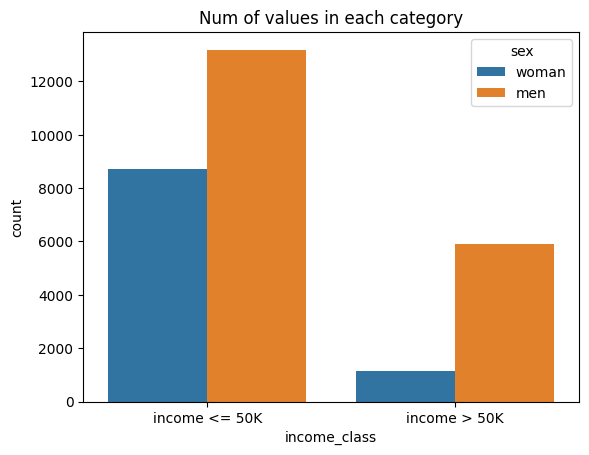

In [7]:
plt.figure()
fig = sns.countplot(data=train_data[["income_class","sex"]],
                    x="income_class",
#                     stat="proportion",
                    hue="sex")
fig.set_xticklabels(['income <= 50K','income > 50K'])
plt.legend(title='sex', labels=['woman', 'men'])
plt.title("Num of values in each category")
plt.show()
plt.close()

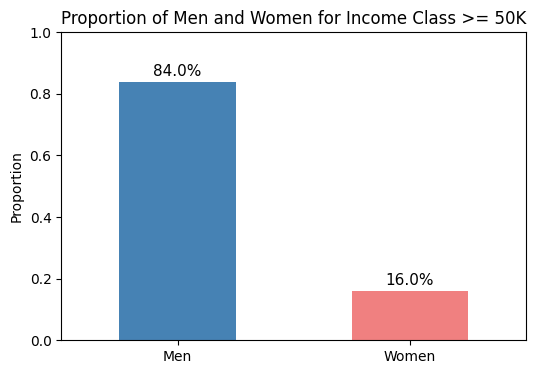

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Filter to income_class = 1
subset = train_data[train_data["income_class"] == 1]

# Compute proportions
prop = subset["sex"].value_counts(normalize=True)

# Map numeric sex to names (only if needed)
sex_labels = {
    1: "Men",
    0: "Women",
    "Male": "Men",
    "Female": "Women"
}
prop.index = prop.index.map(lambda x: sex_labels.get(x, x))

# Choose custom colors
colors = ["steelblue", "lightcoral"]  # Men, Women

# Plot
ax = prop.plot(
    kind="bar",
    figsize=(6,4),
    color=colors
)

plt.ylabel("Proportion")
plt.title("Proportion of Men and Women for Income Class >= 50K")
plt.xticks(rotation=0)
plt.ylim(0, 1)

# Add percentages above bars
for i, v in enumerate(prop):
    ax.text(i, v + 0.02, f"{v*100:.1f}%", ha="center", fontsize=11)

plt.show()

### Data Scalling

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = pd.DataFrame(scaler.fit_transform(train_data[features]),columns = features)

X_test = pd.DataFrame(scaler.transform(test_data[features]),columns = features) # note that here we just use the transform method!

The dataset is quite imbalance between a gender, so we expect our model to be unfair.
The source of the bias is coming from our societal bias.

# A2. Train a Model
let's train our model and analyse the results.

In [10]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=15)

model.fit(X = X_train[features],
          y = train_data[target_column])

KNeighborsClassifier(n_neighbors=15)

In [11]:
from sklearn.metrics import accuracy_score

In [12]:
test_data[target_column]

0        0
1        0
2        1
3        1
4        0
        ..
16276    0
16277    0
16278    0
16279    0
16280    1
Name: income_class, Length: 15175, dtype: int64

In [13]:
predictions = model.predict(X_test[features])
accuracy = accuracy_score(y_true=test_data[target_column], y_pred=predictions)

In [14]:
accuracy

0.8392751235584843

In [15]:
acc_score = accuracy_score(y_true = test_data[target_column],
                           y_pred = model.predict(X_test[features]))
print("Accuracy_score:", acc_score)

Accuracy_score: 0.8392751235584843


# A3. Analysis of Model Fairness

There is no single definition of fairness. Many competing definitions exist for measuring whether a model is statistically "fair".

Different definitions focus on different aspects of fairness, so the right choice **depends on the application**. Choosing one requires thinking carefully about the project's goals, and discussing them with the data scientists, the decision-makers, and the people affected by the model.

**Notation:** $Y$ is the true label, $\hat{Y}$ is the model's prediction, and $A$ is the sensitive attribute (e.g. race), with groups $a$ and $b$.

Some of the most widely used definitions are:

1. **Demographic Parity:** equal rate of positive predictions across groups.
   $P(\hat{Y}=1 \mid A=a) = P(\hat{Y}=1 \mid A=b)$
2. **Equal Opportunity:** equal true positive rates across groups.
   $P(\hat{Y}=1 \mid Y=1, A=a) = P(\hat{Y}=1 \mid Y=1, A=b)$
3. **Equalized Odds:** equal true positive rates *and* equal false positive rates across groups.
   $P(\hat{Y}=1 \mid Y=y, A=a) = P(\hat{Y}=1 \mid Y=y, A=b)$ for $y \in \{0,1\}$
4. **Predictive Parity:** equal precision (positive predictive value) across groups.
   $P(Y=1 \mid \hat{Y}=1, A=a) = P(Y=1 \mid \hat{Y}=1, A=b)$
5. **Equal Accuracy:** equal overall accuracy across groups.
   $P(\hat{Y}=Y \mid A=a) = P(\hat{Y}=Y \mid A=b)$

⚠️ These definitions often **conflict**. So we canot satisfie more of some in the same time.

A good approach is to start from the **social and policy goals** of the application, and then translate them into the **statistical properties** we want the model to have. Most definitions split the population into groups and compare a metric across those groups.

In [17]:
predictions = model.predict(X_test[features])
predictions = pd.Series(predictions,index = test_data.index)
sensitive_atribute = test_data[sensitive_feature]

In [18]:
woman_mask = sensitive_atribute == 0
predictions_woman = predictions.loc[woman_mask]
labels_woman = test_data.loc[woman_mask, target_column]

acc_score1 = accuracy_score(y_true = labels_woman,
                            y_pred = predictions_woman)
print("Accuracy_score:", acc_score1)

Accuracy_score: 0.9182279469164715


In [19]:
man_mask = sensitive_atribute == 1
predictions_man = predictions.loc[man_mask]
labels_man = test_data.loc[man_mask, target_column]

acc_score2 = accuracy_score(y_true = labels_man,
                           y_pred = predictions_man)
print("Accuracy_score:", acc_score2)

Accuracy_score: 0.7990249726395383


In [20]:
Diffrence_on_accuracy = np.abs(acc_score1 - acc_score2)
Diffrence_on_accuracy

0.11920297427693316

## F1. Demographic Parity

Demographic parity requires the **rate of positive predictions** to be the same in every sensitive group.

---

> **Definition (Demographic Parity).** A predictor $\hat{Y}$ satisfies **demographic parity** if its predictions are independent of the sensitive attribute $S$, written $\hat{Y} \perp S$. Equivalently:
>
> $$\Pr(\hat{Y}=1 \mid S=s) = \Pr(\hat{Y}=1), \quad \text{for every value } s \text{ of } S.$$

When there are two sensitive groups, $s \in \{0,1\}$, we measure how far the model is from demographic parity with the **demographic parity difference**:

$$\Delta_{DP} = \left|\, \Pr(\hat{Y}=1 \mid S=0) - \Pr(\hat{Y}=1 \mid S=1) \,\right|$$

$\Delta_{DP} = 0$ means perfect demographic parity. The larger $\Delta_{DP}$ is, the more biased the model.

---

In [21]:
def demographic_parity_difference(predictions, sensitive_atribute):
    """
    Implementation of demographic parity difference for different groups of sensitive attribute
    1. For each group calculate the proportion of accepted rate.
    2. Find the maximum and the minim group.
    3. Calculate the difference.
    """
    # 1. For each group calculate the proportion of positive predictions.
    # group 0 
    group0_mask = sensitive_atribute == 0
    predictions_group0 = predictions[group0_mask]

    positive_rate_group0 = np.sum(predictions_group0 == 1)*1/ predictions_group0.shape[0]

    # group 1 
    group1_mask = sensitive_atribute == 1
    predictions_group1 = predictions[group1_mask]

    positive_rate_group1 = np.sum(predictions_group1 == 1)*1 / predictions_group1.shape[0]
    
    # 3. Calculate the different.
    difference = np.abs(positive_rate_group0-positive_rate_group1)
    
    return difference, [positive_rate_group0, positive_rate_group1]

In [22]:
predictions = model.predict(X_test[features])
sensitive_attribute = test_data["sex"]

In [23]:
demographic_metric, rates = demographic_parity_difference(predictions, sensitive_attribute)

In [24]:
print(f"Demographic parity difference is: {round(demographic_metric,5)}")

Demographic parity difference is: 0.1965


In [25]:
print(f"The rate of different groups are: {rates}")

The rate of different groups are: [0.07650273224043716, 0.27300766092926076]


**Potential issues**

1. **Laziness:** Demographic parity only looks at *how many* people get a positive prediction, not *who* gets it. For example, a model could accept the most qualified people in group $S=1$ and accept people **at random** in group $S=0$, at the same rate, and still satisfy demographic parity. In practice this is less likely, because we train models to optimise a performance metric, but demographic parity alone does not rule it out.

2. **Conflict with accuracy:** If the true positive rates in the data (the **base rates**) differ between groups, $\Pr(Y=1 \mid S=0) \neq \Pr(Y=1 \mid S=1)$, then even a **perfect classifier** ($\hat{Y}=Y$) violates demographic parity. So enforcing demographic parity means accepting some loss in accuracy.

---

# B. Mitigating Bias

Many recent papers propose methods to make machine learning models fairer. They fall into three general families, depending on **when** we intervene:

1. **Pre-processing (fix the data):** change the training data before training the model. *E.g. re-weight or re-sample examples so that groups are balanced, or transform features so they carry less information about the sensitive attribute.*
2. **In-processing (fix the training):** change the learning algorithm itself. *E.g. add a fairness penalty or constraint to the loss function.*
3. **Post-processing (fix the predictions):** change the model's outputs after training. *E.g. use a different classification threshold for each group.*

For an overview of fairness definitions and mitigation methods, see the survey by Pessach & Shmueli, [*Algorithmic Fairness*](https://arxiv.org/abs/2001.09784) (2020).

## F2. Equal Opportunity

Equal opportunity requires every group to have the same **true positive rate**. Among the people who truly belong to the positive class, each group should have the same chance of being predicted positive.

---

> **Definition (Equal Opportunity).** A predictor $\hat{Y}$ satisfies **equal opportunity** if its predictions are independent of the sensitive attribute $S$, conditional on the true outcome being positive ($Y=1$), written $\hat{Y} \perp S \mid Y=1$. Equivalently:
>
> $$\Pr(\hat{Y}=1 \mid S=s,\, Y=1) = \Pr(\hat{Y}=1 \mid Y=1), \quad \text{for every value } s \text{ of } S.$$

When there are two sensitive groups, $s \in \{0,1\}$, we measure how far the model is from equal opportunity with the **equal opportunity difference**:

$$\Delta_{EOpp} = \left|\, \Pr(\hat{Y}=1 \mid S=0,\, Y=1) - \Pr(\hat{Y}=1 \mid S=1,\, Y=1) \,\right|$$

$\Delta_{EOpp} = 0$ means perfect equal opportunity.

---

In [26]:
def equalized_opportunities_difference(predictions, actual, sensitive_attribute):
    """
    Implementation of demographic parity difference for different groups of sensitive attribute
    1. For each group calculate the proportion of positive predictions.
    2. Calculate the difference.
    """
    # 1. For each group calculate the proportion of positive predictions.
    # group 0 
    true_positive_mask = test_data[target_column]==1
    group0_mask = sensitive_attribute == 0
    predictions_group0 = predictions[np.logical_and(group0_mask, true_positive_mask)]

    true_positive_rate_group0 = np.sum(predictions_group0 == 1)*1/ predictions_group0.shape[0]

    # group 1 
    group1_mask = sensitive_attribute == 1
    predictions_group1 = predictions[np.logical_and(group1_mask, true_positive_mask)]

    true_positive_rate_group1 = np.sum(predictions_group1 == 1)*1 / predictions_group1.shape[0]
    
    # 3. Calculate the different.
    difference = np.abs(true_positive_rate_group0-true_positive_rate_group1)
    
    return difference, [true_positive_rate_group0, true_positive_rate_group1]

In [27]:
predictions = model.predict(X_test[features])
sensitive_attribute = test_data["sex"]
actual = test_data[target_column]

In [28]:
equalized_opportunities_metric, _ = equalized_opportunities_difference(predictions, actual, sensitive_attribute)

In [29]:
print(f"equalized opportunities difference is: {round(equalized_opportunities_metric,5)}")

equalized opportunities difference is: 0.14431


In [30]:
predictions = model.predict(X_test[features])

In [31]:
results = pd.DataFrame([acc_score,
                        demographic_metric,
                        equalized_opportunities_metric], 
                       index = ["accuracy",
                                "demographic_metric",
                                "equalized_opportunities"],
                       columns = ["model"])

In [32]:
results = pd.DataFrame([acc_score,
                        demographic_metric,
                        equalized_opportunities_metric], 
                       index = ["accuracy",
                                "demographic_metric",
                                "equalized_opportunities"],
                       columns = ["model"])

In [33]:
results

,model
accuracy,0.839275
demographic_metric,0.196505
equalized_opportunities,0.144309


In [35]:
def compute_metric(y_pred, data, sensitive_feature):
    # get all metrics
    acc_score = accuracy_score(y_true=data[target_column], y_pred=y_pred)
    
    demographic_metric, _ = demographic_parity_difference(y_pred,
                                                          sensitive_feature)
    
    equalized_opportunities_metric, _ = equalized_opportunities_difference(y_pred,
                                                                           data,
                                                                          sensitive_feature)
    return {
            "accuracy": acc_score,
            "demographic_metric": demographic_metric,
            "equalized_opportunities" : equalized_opportunities_metric
            }

# B. Mitigating Bias

Many recent papers propose methods to make machine learning models fairer. They fall into three general families, depending on **when** we intervene:

1. **Pre-processing (fix the data):** change the training data before training the model. *E.g. re-weight or re-sample examples so that groups are balanced, or transform features so they carry less information about the sensitive attribute.*
2. **In-processing (fix the training):** change the learning algorithm itself. *E.g. add a fairness penalty or constraint to the loss function.*
3. **Post-processing (fix the predictions):** change the model's outputs after training. *E.g. use a different classification threshold for each group.*

**Further reading**
- D. Pessach & E. Shmueli, [*A Review on Fairness in Machine Learning*](https://arxiv.org/abs/2001.09784), 2022.  
  Fairness definitions and pre-, in- and post-processing methods.
- S. Barocas, M. Hardt & A. Narayanan, [*Fairness and Machine Learning: Limitations and Opportunities*](https://fairmlbook.org/), 2023.    
  Free online textbook covering the criteria, their limits, and the broader context.
- N. Mehrabi et al., [*A Survey on Bias and Fairness in Machine Learning*](https://arxiv.org/abs/1908.09635), 2021.  
  Sources of bias and fairness definitions.

### 1. Pre-Processing

Unfair models often come from **bias in the data**. Pre-processing methods remove this bias *before* training: we transform the data, then train any model on it as usual.

Pre-processing techniques work by transforming the data into a different representation to remove bias. Common approaches include re-balancing techniques, removing sensitive features and their proxy variables, or using machine learning techniques, such as representation learning, to transform the data into a fair representation.


**Pros:**
1. **Model-agnostic:** the cleaned data can be used with any model and for any downstream task.

**Cons:**
1. **May reduce performance** (e.g. lower accuracy).
2. **No guarantee:** fair data does not guarantee a fair final model, because the model can still introduce bias.

### 2. In-Processing

In-processing methods incorporate fairness **into the training** of a classifier. In general, they add constraints or regularization terms to the objective function during training. Different methods have been proposed, either as general frameworks or for specific classification algorithms.

**Pros:**
1. Good performance on both accuracy and fairness measures.
2. Flexible trade-off between performance and fairness.
3. No need for the sensitive feature at prediction time (only during training).

**Cons:**
1. Some fairness constraints are hard to optimise (e.g. not differentiable).
2. Requires modifying the classifier, so methods are often limited to specific classifiers.

### 3. Post-Processing

Post-processing methods adjust the **output scores** of an already trained classifier to remove bias. The most common technique uses a different classification threshold for each group so that a fairness criterion is satisfied (e.g. Hardt et al., 2016).

**Pros:**
1. Relatively good performance, especially on fairness measures.
2. No need to modify or retrain the classifier, so it works with any model (even a black box).

**Cons:**
1. Often requires access to the sensitive attribute at prediction time.
2. Usually achieves a worse accuracy–fairness trade-off than in-processing, since the model itself is not changed.
3. Using different thresholds per group means explicitly treating groups differently, which may not be allowed legally in some applications.

# Pre-Processing

### B1. Fairness Through Unawareness

A very intuitive but **wrong** solution is to assume that if we simply **remove the sensitive feature** from the data, we will get a fair classifier.

This does not work because other features can be **correlated** with the sensitive feature (so-called **proxy variables**), and the model can still learn it through them.

We will now build an **unawareness** classifier (trained without the sensitive feature) and compare its results with our previous classifier.

In [36]:
non_sensitive_features = features.difference([sensitive_feature])

In [37]:
from sklearn.neighbors import KNeighborsClassifier
unaware_model  = KNeighborsClassifier(n_neighbors=15)

unaware_model.fit(X = X_train[non_sensitive_features],
                  y = train_data[target_column])

KNeighborsClassifier(n_neighbors=15)

In [38]:
unaware_metrics = compute_metric(y_pred = unaware_model.predict(X_test[non_sensitive_features]),
                                 data = test_data,
                                 sensitive_feature = test_data["sex"])

In [39]:
unaware_results = pd.DataFrame(unaware_metrics,
                               index = ["unaware_model"]).T

In [40]:
unaware_results

,unaware_model
accuracy,0.839209
demographic_metric,0.183257
equalized_opportunities,0.110204


## Compare the results of 2 models

In [41]:
all_results = pd.concat([results, unaware_results],axis=1)
all_results

,model,unaware_model
accuracy,0.839275,0.839209
demographic_metric,0.196505,0.183257
equalized_opportunities,0.144309,0.110204


<AxesSubplot: >

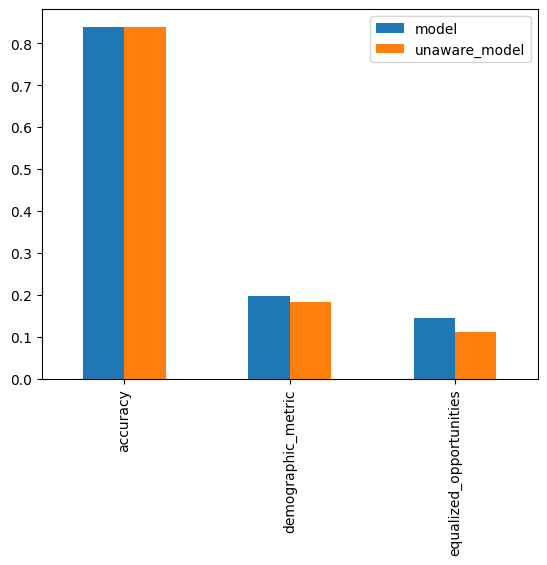

In [42]:
all_results.plot(kind="bar")

### Conclusion

Removing the sensitive feature is **not enough** to remove bias.  
Other features still leak information about the sensitive attribute, so the model can learn it indirectly.

### B2. Removing Correlated Features

The results above suggest that our sensitive feature is **correlated** with some of the non-sensitive features.

We will now find those features and remove them too, to see whether this improves fairness.

In [43]:
corr = {}
for f in non_sensitive_features:
    corr[f] =np.corrcoef(test_data[sensitive_feature], test_data[f])[0,1]
corr = np.abs(pd.DataFrame(data=corr, index=["corr"]).T).sort_values(by="corr",ascending = False)

<Figure size 640x480 with 0 Axes>

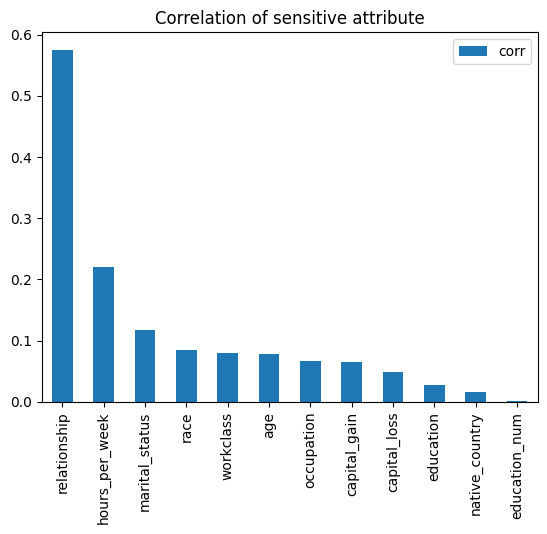

In [44]:
plt.figure()
corr.plot(kind="bar")
plt.title("Correlation of sensitive attribute")
plt.show()
plt.close()

#### Iteratively Exclude Correlated Features

Let's build a classifier while progressively removing the most correlated features in each step. This helps us see how removing correlated features affects model accuracy.

### Assignment part 1

1. **Remove features one by one.** For $k = 0, 1, \dots, K$:
   - Remove the sensitive variable $S$ and the $k$ features most correlated with it.
   - Train a classifier on the rest.
   -  Compute accuracy, $\Delta_{DP}$ and $\Delta_{EOdds}$ on the test set.
2. **Compare all models in one plot.** Plot accuracy, $\Delta_{DP}$, $\Delta_{EOpp}$ and $\Delta_{EOdds}$ for:
   - the baseline model from Section A,
   - the unawareness model from B1,
   - the models from step 1.

### Assignment part 2
1. Implement a function `equalized_odds_difference` that computes $\Delta_{EOdds}$ as defined above.
2. Use it to evaluate:
   - the **baseline model** from Section A, and
   - the `unaware_model` from Section B1.
3. Compare the two values. Does removing the sensitive feature improve equalized odds?

*Note: you do **not** need to retrain the models. Use the predictions you already have.*

## F3. Equalized Odds

**Equalized odds**, also called **separation**, requires every group to have the same **true positive rate (TPR)** *and* the same **false positive rate (FPR)**.

---

> **Definition (Equalized Odds).** A predictor $\hat{Y}$ satisfies **equalized odds** if its predictions are independent of the sensitive attribute $S$, conditional on the true outcome $Y$, written $\hat{Y} \perp S \mid Y$. Equivalently:
>
> $$\Pr(\hat{Y}=1 \mid S=s,\, Y=y) = \Pr(\hat{Y}=1 \mid Y=y), \quad \text{for every value } s \text{ of } S \text{ and } y \in \{0,1\}.$$

When there are two sensitive groups, $s \in \{0,1\}$, we want **both** of the following to hold:

$$\underbrace{\Pr(\hat{Y}=1 \mid S=0,\, Y=1) = \Pr(\hat{Y}=1 \mid S=1,\, Y=1)}_{\text{equal TPR}}$$

$$\underbrace{\Pr(\hat{Y}=1 \mid S=0,\, Y=0) = \Pr(\hat{Y}=1 \mid S=1,\, Y=0)}_{\text{equal FPR}}$$

We measure how far the model is from equalized odds with the **equalized odds difference**:

$$\Delta_{EOdds} = \left|\, \mathrm{TPR}_0 - \mathrm{TPR}_1 \,\right| + \left|\, \mathrm{FPR}_0 - \mathrm{FPR}_1 \,\right|$$

$\Delta_{EOdds} = 0$ means perfect equalized odds. Note that equal opportunity (F2) is the special case that only asks for equal TPR.

---

# Things to Remember

1. **ML models can be biased for many reasons.** Bias in the data is the most common source.
2. **There is no single definition of fairness.** The right criterion depends on the application, and different criteria often **cannot be satisfied at the same time**.
3. **Fairness metrics compare rates across groups**, e.g. positive prediction rate (demographic parity), true positive rate (equal opportunity), or true and false positive rates (equalized odds).
4. **Removing sensitive features does not guarantee fairness**, because proxy variables still carry the same information. Often it barely changes the model's behaviour.
5. **Bias can be mitigated** with pre-processing, in-processing, or post-processing methods.
6. **There is a trade-off between fairness and performance.** The right method depends on how much accuracy we are willing to give up for fairness.
7. **Compute fairness metrics on the test set**, not on the training set. Like accuracy, fairness must be measured on **unseen data**: a model can look fair on the data it was trained on, but not on new people.

**Further reading**
- D. Pessach & E. Shmueli, [*A Review on Fairness in Machine Learning*](https://arxiv.org/abs/2001.09784), ACM Computing Surveys, 2022.
- S. Barocas, M. Hardt & A. Narayanan, [*Fairness and Machine Learning*](https://fairmlbook.org/), MIT Press, 2023 (free online).

**Fairness libraries in Python**
- [AIF360](https://aif360.readthedocs.io/en/stable/modules/algorithms.html) (IBM): many fairness metrics and mitigation algorithms.
- [Fairlearn](https://fairlearn.org/) (Microsoft): fairness metrics, mitigation methods, and visualisation tools.